[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_18/MFM_ch18_spillover/MFM_ch18_spillover.ipynb)

# MFM_ch18_spillover

Diebold-Yilmaz connectedness of 13 banks: vector autoregression (VAR) on log Parkinson volatility, generalized forecast error variance decomposition at 10 days, connectedness table and the network of net pairwise spillovers.

Each row attributes one bank's forecast-error variance to shocks associated with the column banks; the unrounded row sums to 100%. FROM is the off-diagonal row sum; TO is the off-diagonal column sum; NET = TO − FROM. TO sums contributions to other banks and need not be below 100. For JPM, the displayed TO 86.2 minus FROM 76.4 gives NET 9.8 percentage points. Total connectedness is the average FROM across the 13 banks.

Generalized forecast error variance decomposition describes predictive variance attribution, not structural causation; different market closing times may affect the estimated links.

Larger network nodes indicate larger TO; thicker arrows indicate larger positive pairwise net spillovers. Only the strongest quarter of positive pairwise links is shown. A bank can be an aggregate net receiver and a net transmitter to a particular other bank. Heatmap cells are rounded, and the heatmap’s colours saturate above 40%; read the printed cell values for larger shares. The return-based and log-volatility-based totals concern different forecast targets and are not interchangeable. Static lag order is chosen by the Bayesian information criterion (BIC).

*Modelling Financial Markets (MFM), Chapter 18: Systemic Risk and Networks. Author: Daniel Traian Pele.*

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from scipy.stats import spearmanr
import statsmodels.api as sm
from statsmodels.regression.quantile_regression import QuantReg
from sklearn.linear_model import QuantileRegressor, ElasticNetCV
from scipy import optimize
try:
    from arch import arch_model
except ImportError:                      # Colab: the arch package is not preinstalled
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'arch'])
    from arch import arch_model
import warnings
warnings.filterwarnings('ignore')

## Style and helpers

In [2]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Course colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Teal     = '#17A2B8'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
REGION_COL = {'US': MainBlue, 'EU': IDAred, 'RO': Forest}
REGION_LAB = {'US': 'US banks', 'EU': 'European banks', 'RO': 'Romanian banks (BVB)'}
EVENTS = [('2011-08-08', 'Euro crisis'), ('2016-06-24', 'Brexit vote'), ('2018-12-19', 'RO bank tax'),
          ('2020-03-16', 'COVID-19'), ('2023-03-13', 'SVB'), ('2025-04-07', 'Tariffs')]

HERE = '.'
FIGURE_OUT_DIR = globals().get('OUT_DIR', '.')
os.makedirs(FIGURE_OUT_DIR, exist_ok=True)
SEED = 42
B_BOOT = 999
RESULTS = {}


def save_fig(name):
    """Save the figure as transparent PDF and PNG in the selected output folder."""
    plt.savefig(os.path.join(FIGURE_OUT_DIR, f'{name}.pdf'), bbox_inches='tight', transparent=True)
    plt.savefig(os.path.join(FIGURE_OUT_DIR, f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def jsonable(x):
    if isinstance(x, dict):
        return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [jsonable(v) for v in x]
    if isinstance(x, np.ndarray):
        return [jsonable(v) for v in x.tolist()]
    if isinstance(x, (np.floating, np.integer)):
        return x.item()
    if isinstance(x, pd.Timestamp):
        return str(x.date())
    return x


def mark_events(ax, ymax=None):
    """Vertical reference lines for events, with black labels."""
    for d, lab in EVENTS:
        t = pd.Timestamp(d)
        if ax.get_xlim()[0] <= mdates.date2num(t) <= ax.get_xlim()[1]:
            ax.axvline(t, color=Gray, lw=0.5, ls=':')
            ax.text(t, ax.get_ylim()[1] if ymax is None else ymax, lab, rotation=90, fontsize=6.5, color='black',
                    ha='right', va='top')

## Data

In [3]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
START = '2010-01-01'
END = '2026-09-18'

# bank -> (symbol, name, region)
BANKS = {
    'JPM':  ('JPM.US',    'JPMorgan Chase',       'US'),
    'BAC':  ('BAC.US',    'Bank of America',      'US'),
    'C':    ('C.US',      'Citigroup',            'US'),
    'GS':   ('GS.US',     'Goldman Sachs',        'US'),
    'MS':   ('MS.US',     'Morgan Stanley',       'US'),
    'WFC':  ('WFC.US',    'Wells Fargo',          'US'),
    'DBK':  ('DBK.XETRA', 'Deutsche Bank',        'EU'),
    'BNP':  ('BNP.PA',    'BNP Paribas',          'EU'),
    'SAN':  ('SAN.MC',    'Santander',            'EU'),
    'INGA': ('INGA.AS',   'ING',                  'EU'),
    'HSBA': ('HSBA.LSE',  'HSBC',                 'EU'),
    'TLV':  ('TLV.RO',    'Banca Transilvania',   'RO'),
    'BRD':  ('BRD.RO',    'BRD-Groupe SG',        'RO'),
}
US = [k for k, v in BANKS.items() if v[2] == 'US']
EU = [k for k, v in BANKS.items() if v[2] == 'EU']
RO = [k for k, v in BANKS.items() if v[2] == 'RO']
ALL = US + EU + RO
NAMES = {k: v[1] for k, v in BANKS.items()}
INDICES = {'SPX': ('GSPC.INDX', 'S&P 500'), 'SX5E': ('STOXX50E.INDX', 'Euro Stoxx 50'),
           'BET': ('BET', 'BET'), 'VIX': ('VIX.INDX', 'VIX')}
REGION_INDEX = {'US': 'SPX', 'EU': 'SX5E', 'RO': 'BET'}


def artificial_fill(d):
    """Rows that repeat the previous close and show no trading: an artificial non-trading-day fill.

    A repeated close is a fill only if the row itself shows no trading: zero volume (for files that report
    volume), no intraday range (open = high = low = close) or a copy of the previous row in every field. A
    repeated close on a day with volume and an intraday range is a genuine unchanged close (a zero return)
    and is kept. Files with closes only (the BET) give no such evidence, so every row is kept.
    """
    repeat = d['close'].diff() == 0
    no_trade = pd.Series(False, index=d.index)
    if 'volume' in d and (d['volume'] > 0).mean() > 0.5:
        no_trade |= d['volume'].fillna(0) <= 0
    if {'open', 'high', 'low'} <= set(d.columns):
        no_trade |= (d['open'] == d['high']) & (d['high'] == d['low']) & (d['low'] == d['close'])
        fields = [c for c in ['open', 'high', 'low', 'close', 'volume'] if c in d]
        no_trade |= (d[fields] == d[fields].shift()).all(axis=1)
    return repeat & no_trade


def read_market(symbol):
    """Read the daily price series of one symbol from the course data."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def bank_frame(key, start=START, end=END):
    """Daily prices and volume of one bank, with the adjusted price and the corrections above."""
    symbol, _, region = BANKS[key]
    d = read_market(symbol).loc[start:end].copy()
    d = d[(d.index.dayofweek < 5) & (d['adjusted_close'] > 0)]
    if region == 'RO':
        d = d[d['volume'] > 0]                                   # days without trades
    if key == 'TLV' and pd.Timestamp('2016-05-30') in d.index:
        # bonus-share adjustment: the post-ex-date factor also applies on 30 May 2016
        f = d.loc['2016-05-31', 'adjusted_close'] / d.loc['2016-05-31', 'close']
        d.loc['2016-05-30', 'adjusted_close'] = d.loc['2016-05-30', 'close'] * f
    return d


def bank_price(key, start=START, end=END):
    return bank_frame(key, start, end)['adjusted_close'].rename(key)


def index_close(key, start=START, end=END):
    d = read_market(INDICES[key][0]).loc[start:end]
    d = d[(d.index.dayofweek < 5) & (d['close'] > 0)].dropna(subset=['close'])
    if key != 'VIX':
        d = d[~artificial_fill(d)]                               # non-trading days filled with the previous price
    return d['close'].rename(key)


def prices(keys, start=START, end=END):
    """Daily prices of banks and/or indices, on common trading days only."""
    cols = [bank_price(k, start, end) if k in BANKS else index_close(k, start, end) for k in keys]
    return pd.concat(cols, axis=1, join='inner').dropna()


def joint_returns(keys, start=START, end=END):
    """Log returns in % between common dates: prices are aligned on common trading days first, then returns are
    computed. A return spans several sessions of a market that traded on dates dropped from the intersection."""
    return 100 * np.log(prices(keys, start, end)).diff().dropna()


def bank_range_vol(keys, start=START, end=END, zero_range='floor'):
    """Daily Parkinson volatility (in %, annualised), on the days common to all banks.

    Days with high = low (zero range) or a missing range: zero_range='floor' replaces the variance by the smallest
    positive value observed up to that day (a regularisation before taking logs, no look-ahead; imputed values, not
    observed Parkinson estimates); zero_range='drop' removes those days."""
    out = []
    for k in keys:
        d = bank_frame(k, start, end)
        rng = np.log(d['high'] / d['low']).where(d['high'] > d['low'])
        s2 = rng ** 2 / (4 * np.log(2))
        if zero_range == 'floor':
            floor = s2.where(s2 > 0).cummin().ffill()              # smallest positive value observed UP TO day t
            s2 = s2.fillna(floor)
        out.append((100 * np.sqrt(252 * s2)).rename(k))
    return pd.concat(out, axis=1, join='inner').dropna()


def system_return(R, members):
    """System return: equal-weighted portfolio of the banks (log returns in %, daily approximation)."""
    return R[members].mean(axis=1)


# daily log returns in % (common days) and log Parkinson volatility
R = joint_returns(ALL + ['SPX', 'SX5E', 'BET', 'VIX'])
V = np.log(bank_range_vol(ALL))
print(R.index[0].date(), '->', R.index[-1].date(), len(R), 'common days')


def system_ex(k, members):
    """Return of the regional system without bank k (equal-weighted portfolio)."""
    return R[[j for j in members if j != k]].mean(axis=1)


def region_of(k):
    return BANKS[k][2]

2010-01-05 -> 2026-09-18 3961 common days


## Systemic risk measures

In [4]:
def mes(r_i, r_m, alpha=0.05):
    """MES (%): average loss of the bank on the days when the market is in its alpha-probability tail."""
    q = np.quantile(r_m, alpha)
    return -np.mean(np.asarray(r_i)[np.asarray(r_m) <= q])


def mes_threshold(r_i, r_m, c=-2.0):
    """MES (%) on the days when the market falls by more than |c|% (the definition used for LRMES)."""
    return -np.mean(np.asarray(r_i)[np.asarray(r_m) < c])


def lrmes(mes2_pct):
    """Long-run loss in a crisis (market -40% over six months): LRMES = 1 - exp(-18 MES), MES as a fraction."""
    return 1 - np.exp(-18 * mes2_pct / 100)


def srisk_ratio(lrm, leverage, k=0.08):
    """SRISK / market equity W: k(L - 1) - (1 - k)(1 - LRMES), with L = (D + W)/W."""
    return k * (leverage - 1) - (1 - k) * (1 - lrm)


def breakeven_leverage(lrm, k=0.08):
    """Leverage L* above which SRISK > 0: L* = 1 + (1 - k)(1 - LRMES)/k."""
    return 1 + (1 - k) * (1 - lrm) / k


def qreg(y, X, q):
    """Quantile regression (Koenker-Bassett); returns the coefficients [intercept, slopes].

    IRLS with a tight tolerance; if it hits the iteration limit, the exact linear-programming solution (HiGHS) is used."""
    y, Xc = np.asarray(y, float), sm.add_constant(np.asarray(X), has_constant='add')
    with warnings.catch_warnings():
        warnings.simplefilter('error', IterationLimitWarning)
        try:
            return QuantReg(y, Xc).fit(q=q, max_iter=20000, p_tol=QR_TOL).params
        except IterationLimitWarning:
            m = QuantileRegressor(quantile=q, alpha=0.0, fit_intercept=False, solver='highs').fit(Xc, y)
            return m.coef_


def covar_static(x_sys, x_i, alpha=0.01):
    """Unconditional CoVaR and Delta-CoVaR (%, positive = losses).

    Quantile regression at level alpha: X_sys = a + b X_i;
    CoVaR_alpha = -(a + b q_alpha(X_i)); Delta-CoVaR = b (q_50(X_i) - q_alpha(X_i))."""
    x_sys, x_i = np.asarray(x_sys), np.asarray(x_i)
    a, b = qreg(x_sys, x_i, alpha)
    qa, qm = np.quantile(x_i, alpha), np.quantile(x_i, 0.5)
    return {'a': a, 'b': b, 'var_i': -qa, 'covar': -(a + b * qa), 'covar_med': -(a + b * qm),
            'dcovar': b * (qm - qa), 'var_sys': -np.quantile(x_sys, alpha)}


def block_bootstrap_idx(n, block=20, rng=None):
    """Indices for the moving-block bootstrap (Künsch), fixed-length blocks."""
    rng = rng or np.random.default_rng(0)
    starts = rng.integers(0, n - block + 1, size=int(np.ceil(n / block)))
    return (starts[:, None] + np.arange(block)[None, :]).ravel()[:n]


def covar_boot(x_sys, x_i, alpha=0.01, B=200, block=20, seed=0):
    """95% percentile interval for Delta-CoVaR by moving-block bootstrap."""
    x_sys, x_i = np.asarray(x_sys), np.asarray(x_i)
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(B):
        idx = block_bootstrap_idx(len(x_i), block, rng)
        d.append(covar_static(x_sys[idx], x_i[idx], alpha)['dcovar'])
    return np.percentile(d, [2.5, 97.5])


def covar_dynamic(x_sys, x_i, M, alpha=0.01):
    """Time-varying Delta-CoVaR with state variables M_{t-1} (Adrian & Brunnermeier, 2016).

    X_i,t = a + c'M_{t-1} at levels alpha and 50%  ->  VaR_i,t;
    X_sys,t = a + b X_i,t + c'M_{t-1} at level alpha  ->  Delta-CoVaR_t = b (q50_i,t - qalpha_i,t)."""
    ci_a = qreg(x_i, M, alpha)
    ci_m = qreg(x_i, M, 0.5)
    cs = qreg(x_sys, np.column_stack([x_i, M]), alpha)
    Mc = sm.add_constant(np.asarray(M), has_constant='add')
    qa, qm = Mc @ ci_a, Mc @ ci_m
    return pd.DataFrame({'var_i': -qa, 'dcovar': cs[1] * (qm - qa)}, index=getattr(x_i, 'index', None)), cs[1]


def var_fit(Y, p):
    """VAR(p) estimated by OLS; returns the coefficients A_1..A_p (k x k) and the residual covariance matrix."""
    Y = np.asarray(Y, float)
    T, k = Y.shape
    X = np.hstack([np.ones((T - p, 1))] + [Y[p - l - 1:T - l - 1] for l in range(p)])
    Yt = Y[p:]
    B = np.linalg.lstsq(X, Yt, rcond=None)[0]
    E = Yt - X @ B
    S = E.T @ E / (len(Yt) - X.shape[1])
    A = [B[1 + l * k:1 + (l + 1) * k].T for l in range(p)]
    return A, S


def var_bic(Y, pmax=5):
    """VAR order chosen by the Bayesian information criterion (BIC, Schwarz), with the maximum-likelihood residual covariance matrix."""
    Y = np.asarray(Y, float)
    T, k = Y.shape
    best = None
    n = T - pmax
    for p in range(1, pmax + 1):
        A, S = var_fit(Y[pmax - p:], p)
        S_ml = S * (n - 1 - p * k) / n                        # maximum-likelihood covariance E'E / n
        bic = np.log(np.linalg.det(S_ml)) + np.log(n) * p * k * k / n
        if best is None or bic < best[1]:
            best = (p, bic)
    return best[0]


def ma_coefs(A, H):
    """Moving-average coefficients Phi_0..Phi_{H-1}."""
    k = A[0].shape[0]
    Phi = [np.eye(k)]
    for h in range(1, H):
        Phi.append(sum(A[l] @ Phi[h - l - 1] for l in range(min(h, len(A)))))
    return Phi


def gfevd(A, S, H=10):
    """Generalized forecast error variance decomposition (Pesaran-Shin), rows normalised."""
    Phi = ma_coefs(A, H)
    k = S.shape[0]
    num = np.zeros((k, k))
    den = np.zeros(k)
    for P in Phi:
        PS = P @ S
        num += PS ** 2
        den += np.diag(P @ S @ P.T)
    theta = num / np.diag(S)[None, :] / den[:, None]
    return theta / theta.sum(axis=1, keepdims=True)


def spillover_table(theta, names):
    """Connectedness table: contributions (%), FROM, TO, NET and the total index."""
    k = theta.shape[0]
    D = 100 * theta
    off = D - np.diag(np.diag(D))
    frm, to = off.sum(axis=1), off.sum(axis=0)
    tab = pd.DataFrame(D, index=names, columns=names)
    return {'table': tab, 'from': pd.Series(frm, index=names), 'to': pd.Series(to, index=names),
            'net': pd.Series(to - frm, index=names), 'total': off.sum() / k,
            'pairwise_net': pd.DataFrame(off.T - off, index=names, columns=names)}


def rolling_total(Y, window=250, step=5, p=2, H=10):
    """Total connectedness index on rolling windows."""
    Y = pd.DataFrame(Y)
    out, frm_to = {}, {}
    for end in range(window, len(Y) + 1, step):
        w = Y.iloc[end - window:end]
        A, S = var_fit(w.values, p)
        st = spillover_table(gfevd(A, S, H), list(Y.columns))
        out[Y.index[end - 1]] = st['total']
        frm_to[Y.index[end - 1]] = st['net']
    return pd.Series(out), pd.DataFrame(frm_to).T


def check_loss(u, tau):
    return u * (tau - (u < 0))


def lasso_qr_gacv(y, X, tau=0.05, lambdas=None):
    """L1-penalized quantile regression; lambda chosen by the generalized approximate cross-validation criterion
    GACV = sum rho_tau(res) / (n - df), df = effective dimension = number of interpolated observations (zero residuals).

    For the L1 quantile fit with an intercept this count equals 1 + the number of non-zero slopes (checked on the
    windows used in the course); the intercept is part of the model dimension. The number of active slopes (the links
    of the network) is returned separately in 'df' and 'df_sel'."""
    y, X = np.asarray(y, float), np.asarray(X, float)
    n = len(y)
    lambdas = np.logspace(-4, -0.5, 15) if lambdas is None else lambdas
    rows = []
    for lam in lambdas:
        m = QuantileRegressor(quantile=tau, alpha=lam, solver='highs').fit(X, y)
        res = y - m.predict(X)
        n_act = int(np.sum(np.abs(m.coef_) > 1e-8))           # active slopes (links)
        df = int(np.sum(np.abs(res) < 1e-8))                  # interpolated observations (= 1 + n_act here)
        g = check_loss(res, tau).sum() / max(n - df, 1)
        rows.append((lam, g, n_act, m.coef_.copy(), df))
    i = int(np.argmin([r[1] for r in rows]))
    return {'lambda': rows[i][0], 'gacv': [r[1] for r in rows], 'df': [r[2] for r in rows],
            'lambdas': list(lambdas), 'coef': rows[i][3], 'df_sel': rows[i][2],
            'df_gacv': [r[4] for r in rows], 'df_gacv_sel': rows[i][4]}

## Analysis

In [5]:
def spill_static(H=10):
    p = var_bic(V.values, 5)
    A, S = var_fit(V.values, p)
    st = spillover_table(gfevd(A, S, H), ALL)
    ret = R[ALL]
    pr = var_bic(ret.values, 5)
    Ar, Sr = var_fit(ret.values, pr)
    st_r = spillover_table(gfevd(Ar, Sr, H), ALL)
    return st, p, st_r, pr


def fig_spill_table(st):
    """Spillover table; laid out at the size of its box on the slide (5.67 x 2.22 in): full names on the rows,
    tickers on the columns (same order), so that the 13 x 13 cells stay legible."""
    tab = st['table']
    fig = plt.figure(figsize=(5.47, 2.02))
    fig._sf_manual = True
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 0.025], left=0.215, right=0.935, top=0.97, bottom=0.17,
                          wspace=0.03)
    ax = fig.add_subplot(gs[0])
    cax = fig.add_subplot(gs[1])
    im = ax.imshow(tab.values, cmap='Blues', vmin=0, vmax=40, aspect='auto')
    for i in range(len(ALL)):
        for j in range(len(ALL)):
            v = tab.values[i, j]
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=6.3, color='white' if v > 25 else 'black')
    ax.set_xticks(range(len(ALL)))
    ax.set_yticks(range(len(ALL)))
    ax.set_xticklabels(ALL, fontsize=6.6)
    ax.set_yticklabels([NAMES[k] for k in ALL], fontsize=6.6)
    ax.tick_params(length=2)
    ax.set_xlabel('Shock from (column, ticker)', fontsize=6.8, labelpad=2)
    ax.set_ylabel('Forecast error variance of (row)', fontsize=6.8)
    cb = fig.colorbar(im, cax=cax)
    cb.ax.tick_params(labelsize=6.6, length=2)
    cb.set_label('Share of the 10-day forecast\nerror variance (%)', fontsize=6.6)
    save_fig('ch18_spill_table')


def fig_spill_network(st):
    """Network of net pairwise connectedness: arrow from transmitter to receiver, width ~ net effect."""
    pn = st['pairwise_net']                     # pn[i, j] > 0: i is a net transmitter to j
    n = len(ALL)
    ang = np.linspace(np.pi / 2, np.pi / 2 - 2 * np.pi, n, endpoint=False)
    pos = {k: (np.cos(a), np.sin(a)) for k, a in zip(ALL, ang)}
    thr = np.quantile(pn.values[pn.values > 0], 0.75)
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    for i in ALL:
        for j in ALL:
            v = pn.loc[i, j]
            if v > thr:
                (x0, y0), (x1, y1) = pos[i], pos[j]
                ax.annotate('', xy=(x1 * 0.9, y1 * 0.9), xytext=(x0 * 0.9, y0 * 0.9),
                            arrowprops=dict(arrowstyle='-|>', color=Purple, lw=0.4 + 0.9 * v, alpha=0.75,
                                            shrinkA=6, shrinkB=6))
    to = st['to']
    for k in ALL:
        x, y = pos[k]
        ax.scatter(x, y, s=60 + 6 * to[k], color=REGION_COL[region_of(k)], zorder=3)
        ax.text(1.2 * x, 1.14 * y, NAMES[k], ha='left' if x > 0.2 else ('right' if x < -0.2 else 'center'),
                va='center', fontsize=7, color='black')
    ax.set_xlim(-1.75, 1.75)
    ax.set_ylim(-1.35, 1.35)
    ax.axis('off')
    h = [plt.Line2D([], [], marker='o', ls='', color=REGION_COL[r], ms=7) for r in ['US', 'EU', 'RO']]
    h.append(plt.Line2D([], [], color=Purple, lw=1.2))
    ax.legend(h, [REGION_LAB[r] for r in ['US', 'EU', 'RO']] + ['Net pairwise spillover (top 25% of links)'],
              loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=2, frameon=False)
    save_fig('ch18_spill_network')
    return thr

## Further definitions used above

In [6]:
from statsmodels.tools.sm_exceptions import IterationLimitWarning


QR_TOL = 1e-10

## Run

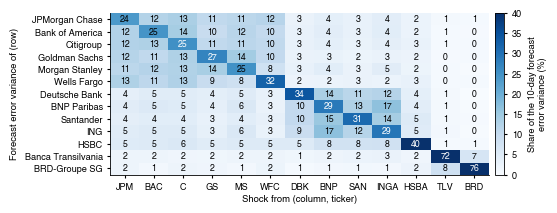

   saved ch18_spill_table


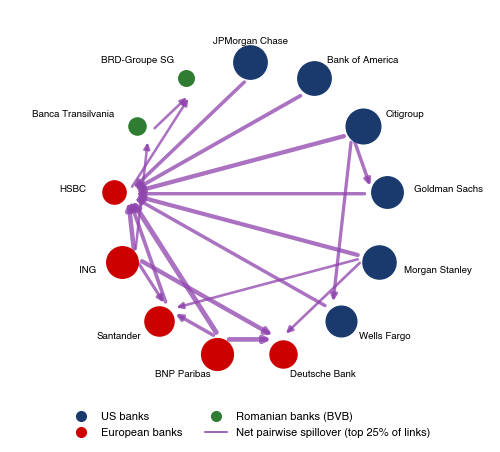

   saved ch18_spill_network
VAR order 2 total connectedness 63.9 (returns: 75.4 )


,to,from,net
JPM,86.2,76.4,9.8
BAC,86.4,75.5,10.9
C,93.8,74.8,19.0
GS,75.4,73.0,2.4
MS,85.0,75.0,9.9
WFC,71.3,67.7,3.6
DBK,53.3,65.9,-12.6
BNP,77.3,71.3,6.0
SAN,63.5,68.9,-5.4
INGA,76.0,70.8,5.2


In [7]:
st, p, st_r, pr = spill_static()
fig_spill_table(st)
fig_spill_network(st)
print('VAR order', p, 'total connectedness', round(st['total'], 1), '(returns:', round(st_r['total'], 1), ')')
pd.DataFrame({'to': st['to'], 'from': st['from'], 'net': st['net']}).round(1)

![ch18_spill_table](./ch18_spill_table.png)

Output: `ch18_spill_table.pdf`

![ch18_spill_network](./ch18_spill_network.png)

Output: `ch18_spill_network.pdf`